# Library guidance before the exercises

**Assumed background:** you know Python and ML theory. These notes focus on unfamiliar libraries and their interfaces, not Python classes or syntax. Read each **Learn first** / **API notes** block before the following task. API notes state purpose, important arguments, input/output shapes or types, and a minimal use example. Your task code and outputs are preserved.

The [Chapter 03 API guide](learning/03_PRACTICAL_GUIDE.md) is also placed inline at the relevant sections. APIs introduced in previous lessons are reused, with compact reminders at their first relevant use in this notebook.

[Practical learning path](learning/START_HERE.md): Chapters 00–02 are the core route; use later vision/transformer/deployment sections only when relevant to your next project.

# Practice outline: pytorch computer vision

This lesson is a sequence of small implementations. Keep the explanatory text as reference, then follow **Your task** immediately above each code cell. You write the implementation; the task names the inputs, APIs, and result to inspect.

| Tasks | What you will build |
| --- | --- |
| [Tasks 1–12](#practice-task-1) | Inspect images and build batched loaders |
| [Tasks 13–20](#practice-task-13) | Train and evaluate a linear baseline |
| [Tasks 21–29](#practice-task-21) | Add nonlinear layers and device-aware helpers |
| [Tasks 30–42](#practice-task-30) | Build and train a CNN; inspect convolution/pooling |
| [Tasks 43–56](#practice-task-43) | Compare models and inspect errors |
| [Tasks 57–61](#practice-task-57) | Save and restore the CNN |

**How to work:** run cells from top to bottom, keep the specified names so later cells can reuse them, and inspect each checkpoint before continuing. Existing code and outputs are preserved. A checkpoint is a result to examine, not a separate test suite. For longer training tasks, write the loop step by step in the same cell.

**On your Mac:** choose CUDA if available, otherwise MPS if available, otherwise CPU. Keep model/input/target devices aligned; use CPU copies when plotting or converting to NumPy. Use `num_workers=0` for notebook DataLoaders. Run lessons with this repository as the working directory. Shared course helpers are supplied in `helper_functions.py` and `going_modular/`; they are support code, not cells you need to fill in.

**Notation:** $N$ is batch/sample count; $C$ is channel/class count as stated locally; image tensors use batch, channels, height, width order. Class-index targets use `torch.int64`; regression and binary-loss targets use `torch.float32`. Accuracy units are stated in each task—do not mix fractions with percentages.

See [LEARNING_GUIDE.md](LEARNING_GUIDE.md) for saving and resuming locally.



<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/03_pytorch_computer_vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[View Source Code](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/03_pytorch_computer_vision.ipynb) | [View Slides](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/slides/03_pytorch_computer_vision.pdf) | [Watch Video Walkthrough](https://youtu.be/Z_ikDlimN6A?t=50417) 

# 03. PyTorch Computer Vision

[Computer vision](https://en.wikipedia.org/wiki/Computer_vision) is the art of teaching a computer to see.

For example, it could involve building a model to classify whether a photo is of a cat or a dog ([binary classification](https://developers.google.com/machine-learning/glossary#binary-classification)).

Or whether a photo is of a cat, dog or chicken ([multi-class classification](https://developers.google.com/machine-learning/glossary#multi-class-classification)).

Or identifying where a car appears in a video frame ([object detection](https://en.wikipedia.org/wiki/Object_detection)).

Or figuring out where different objects in an image can be separated ([panoptic segmentation](https://arxiv.org/abs/1801.00868)).

![example computer vision problems](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-problems.png)
*Example computer vision problems for binary classification, multiclass classification, object detection and segmentation.*

## Where does computer vision get used?

If you use a smartphone, you've already used computer vision.

Camera and photo apps use [computer vision to enhance](https://machinelearning.apple.com/research/panoptic-segmentation) and sort images.

Modern cars use [computer vision](https://youtu.be/j0z4FweCy4M?t=2989) to avoid other cars and stay within lane lines.

Manufacturers use computer vision to identify defects in various products.

Security cameras use computer vision to detect potential intruders.

In essence, anything that can be described in a visual sense can be a potential computer vision problem.

## What we're going to cover

We're going to apply the PyTorch Workflow we've been learning in the past couple of sections to computer vision.

![a PyTorch workflow with a computer vision focus](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-pytorch-computer-vision-workflow.png)

Specifically, we're going to cover:

| **Topic** | **Contents** |
| ----- | ----- |
| **0. Computer vision libraries in PyTorch** | PyTorch has a bunch of built-in helpful computer vision libraries, let's check them out.  |
| **1. Load data** | To practice computer vision, we'll start with some images of different pieces of clothing from [FashionMNIST](https://github.com/zalandoresearch/fashion-mnist). |
| **2. Prepare data** | We've got some images, let's load them in with a [PyTorch `DataLoader`](https://pytorch.org/docs/stable/data.html) so we can use them with our training loop. |
| **3. Model 0: Building a baseline model** | Here we'll create a multi-class classification model to learn patterns in the data, we'll also choose a **loss function**, **optimizer** and build a **training loop**. | 
| **4. Making predictions and evaluating model 0** | Let's make some predictions with our baseline model and evaluate them. |
| **5. Setup device agnostic code for future models** | It's best practice to write device-agnostic code, so let's set it up. |
| **6. Model 1: Adding non-linearity** | Experimenting is a large part of machine learning, let's try and improve upon our baseline model by adding non-linear layers. |
| **7. Model 2: Convolutional Neural Network (CNN)** | Time to get computer vision specific and introduce the powerful convolutional neural network architecture. |
| **8. Comparing our models** | We've built three different models, let's compare them. |
| **9. Evaluating our best model** | Let's make some predictions on random images and evaluate our best model. |
| **10. Making a confusion matrix** | A confusion matrix is a great way to evaluate a classification model, let's see how we can make one. |
| **11. Saving and loading the best performing model** | Since we might want to use our model for later, let's save it and make sure it loads back in correctly. |

## Where can you get help?

All of the materials for this course [live on GitHub](https://github.com/mrdbourke/pytorch-deep-learning).

If you run into trouble, you can ask a question on the course [GitHub Discussions page](https://github.com/mrdbourke/pytorch-deep-learning/discussions) there too.

And of course, there's the [PyTorch documentation](https://pytorch.org/docs/stable/index.html) and [PyTorch developer forums](https://discuss.pytorch.org/), a very helpful place for all things PyTorch. 

## 0. Computer vision libraries in PyTorch

Before we get started writing code, let's talk about some PyTorch computer vision libraries you should be aware of.

| PyTorch module | What does it do? |
| ----- | ----- |
| [`torchvision`](https://pytorch.org/vision/stable/index.html) | Contains datasets, model architectures and image transformations often used for computer vision problems. |
| [`torchvision.datasets`](https://pytorch.org/vision/stable/datasets.html) | Here you'll find many example computer vision datasets for a range of problems from image classification, object detection, image captioning, video classification and more. It also contains [a series of base classes for making custom datasets](https://pytorch.org/vision/stable/datasets.html#base-classes-for-custom-datasets). |
| [`torchvision.models`](https://pytorch.org/vision/stable/models.html) | This module contains well-performing and commonly used computer vision model architectures implemented in PyTorch, you can use these with your own problems. | 
| [`torchvision.transforms`](https://pytorch.org/vision/stable/transforms.html) | Often images need to be transformed (turned into numbers/processed/augmented) before being used with a model, common image transformations are found here. | 
| [`torch.utils.data.Dataset`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) | Base dataset class for PyTorch.  | 
| [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html#module-torch.utils.data) | Creates a Python iterable over a dataset (created with `torch.utils.data.Dataset`). |

> **Note:** The `torch.utils.data.Dataset` and `torch.utils.data.DataLoader` classes aren't only for computer vision in PyTorch, they are capable of dealing with many different types of data.

Now we've covered some of the most important PyTorch computer vision libraries, let's import the relevant dependencies.


### Learn first: Dataset and DataLoader (Tasks 1–12)
A **Dataset** supplies individual examples. `dataset[i]` normally returns `(input, target)` and `len(dataset)` is sample count. A **DataLoader** groups examples into batches and optionally shuffles their order. Its length is **batch count**, not sample count.

Try the interface with tiny tensors before downloading images:

```python
from torch.utils.data import TensorDataset, DataLoader
small_data = TensorDataset(torch.randn(6, 3), torch.tensor([0, 1, 0, 1, 0, 1]))
small_loader = DataLoader(small_data, batch_size=2, shuffle=False, num_workers=0)
for inputs, targets in small_loader:
    print(inputs.shape, targets.shape)  # (2, 3), (2,)
```

| Constructor argument | Meaning |
| --- | --- |
| `dataset` | Dataset object whose examples should be batched |
| `batch_size` | Maximum examples per batch; last batch can be smaller |
| `shuffle` | Randomize sample order; normally True for training and False for testing |
| `num_workers` | Additional data-loading processes; use zero in these Mac notebooks |

`next(iter(loader))` creates an iterator and requests its first batch. It is useful for inspecting the interface; a training epoch instead loops through the entire loader.

`datasets.FashionMNIST(root, train, transform, download)` creates the image dataset: root is the storage folder, train selects the official split, transform preprocesses each retrieved image, and download permits fetching missing data. `ToTensor()` converts PIL images into channel-first float tensors. A grayscale image is $(1,28,28)$; a full batch here is $(32,1,28,28)$. Labels collate into int64 shape $(32,)$.

<a id="practice-task-1"></a>

**Your task 1 — write in the next code cell**

Import torch, nn, torchvision datasets/transforms, ToTensor, and matplotlib.

**Inspect when finished:** These names are available for the image classification workflow.


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.transforms import ToTensor



## 1. Getting a dataset

To begin working on a computer vision problem, let's get a computer vision dataset.

We're going to start with FashionMNIST.

MNIST stands for Modified National Institute of Standards and Technology.

The [original MNIST dataset](https://en.wikipedia.org/wiki/MNIST_database) contains thousands of examples of handwritten digits (from 0 to 9) and was used to build computer vision models to identify numbers for postal services.

[FashionMNIST](https://github.com/zalandoresearch/fashion-mnist), made by Zalando Research, is a similar setup. 

Except it contains grayscale images of 10 different kinds of clothing.

![example image of FashionMNIST](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-fashion-mnist-slide.png)
*`torchvision.datasets` contains a lot of example datasets you can use to practice writing computer vision code on. FashionMNIST is one of those datasets. And since it has 10 different image classes (different types of clothing), it's a multi-class classification problem.*

Later, we'll be building a computer vision neural network to identify the different styles of clothing in these images.

PyTorch has a bunch of common computer vision datasets stored in `torchvision.datasets`.

Including FashionMNIST in [`torchvision.datasets.FashionMNIST()`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html).

To download it, we provide the following parameters:
* `root: str` - which folder do you want to download the data to?
* `train: Bool` - do you want the training or test split?
* `download: Bool` - should the data be downloaded?
* `transform: torchvision.transforms` - what transformations would you like to do on the data?
* `target_transform` - you can transform the targets (labels) if you like too.

Many other datasets in `torchvision` have these parameter options.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `datasets.FashionMNIST(root, train=True, transform=None, download=False)` | Each item gives a grayscale image/label. ToTensor produces float32 $(1,28,28)$; DataLoader adds batch dimension. |
| `transforms.ToTensor()` | Converts a PIL image or supported NumPy image to channel-first tensor. uint8 input is scaled to float values in the unit interval; do not scale it twice. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
datasets.FashionMNIST("data", train=True, transform=ToTensor(), download=True)
preprocess = transforms.ToTensor()
```

<a id="practice-task-2"></a>

**Your task 2 — write in the next code cell**

Download FashionMNIST train and test datasets into data/, using ToTensor as their transform. Save train_data and test_data.

**Inspect when finished:** Image tensors are float32 with shape $(1,28,28)$; labels are integer class indices.


In [15]:
train_data = datasets.FashionMNIST("data", train=True, transform=ToTensor(), download=True)
test_data = datasets.FashionMNIST("data", train=False, transform=ToTensor, download=True)


Let's check out the first sample of the training data.

<a id="practice-task-3"></a>

**Your task 3 — write in the next code cell**

Retrieve the first image and label from train_data. Display both.

**Inspect when finished:** A dataset item is a pair containing an image and its class label.


torch.Size([1, 28, 28])


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

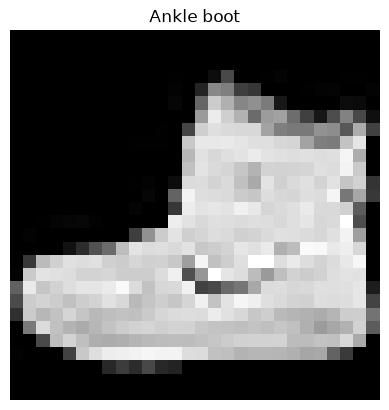

In [ ]:
image, label = train_data[0]


### 1.1 Input and output shapes of a computer vision model

We've got a big tensor of values (the image) leading to a single value for the target (the label).

Let's see the image shape.

<a id="practice-task-4"></a>

**Your task 4 — write in the next code cell**

Inspect image.shape and explain each dimension.

**Inspect when finished:** The first dimension is one grayscale channel, followed by height and width.


In [12]:
print(image.shape)

torch.Size([1, 28, 28])


The shape of the image tensor is `[1, 28, 28]` or more specifically:

```
[color_channels=1, height=28, width=28]
```

Having `color_channels=1` means the image is grayscale.

![example input and output shapes of the fashionMNIST problem](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-input-and-output-shapes.png)
*Various problems will have various input and output shapes. But the premise remains: encode data into numbers, build a model to find patterns in those numbers, convert those patterns into something meaningful.*

If `color_channels=3`, the image comes in pixel values for red, green and blue (this is also known as the [RGB color model](https://en.wikipedia.org/wiki/RGB_color_model)).

The order of our current tensor is often referred to as `CHW` (Color Channels, Height, Width).

There's debate on whether images should be represented as `CHW` (color channels first) or `HWC` (color channels last).

> **Note:** You'll also see `NCHW` and `NHWC` formats where `N` stands for *number of images*. For example if you have a `batch_size=32`, your tensor shape may be `[32, 1, 28, 28]`. We'll cover batch sizes later.

PyTorch generally accepts `NCHW` (channels first) as the default for many operators.

However, PyTorch also explains that `NHWC` (channels last) performs better and is [considered best practice](https://pytorch.org/blog/tensor-memory-format-matters/#pytorch-best-practice). 

For now, since our dataset and models are relatively small, this won't make too much of a difference.

But keep it in mind for when you're working on larger image datasets and using convolutional neural networks (we'll see these later).

Let's check out more shapes of our data.

<a id="practice-task-5"></a>

**Your task 5 — write in the next code cell**

Display training/test image and target counts.

**Inspect when finished:** There are 60000 training examples and 10000 test examples.


In [31]:
train_len = len(train_data.data)
test_len = len(test_data)

print(f"Training images: {len(train_data.data)}")
print(f"Test images: {len(test_data.data)}")

Training images: 60000
Test images: 10000


So we've got 60,000 training samples and 10,000 testing samples.

What classes are there?

We can find these via the `.classes` attribute.

<a id="practice-task-6"></a>

**Your task 6 — write in the next code cell**

Save class_names from train_data.classes and display the names and class-to-index mapping.

**Inspect when finished:** Ten class names map to indices zero through nine.


In [ ]:
class_names = train_data.classes

for i in range(10):
    print(f"index of {class_names[i]}: {i}")

index of T-shirt/top:      0
index of Trouser:      1
index of Pullover:      2
index of Dress:      3
index of Coat:      4
index of Sandal:      5
index of Shirt:      6
index of Sneaker:      7
index of Bag:      8
index of Ankle boot:      9


Sweet! It looks like we're dealing with 10 different kinds of clothes.

Because we're working with 10 different classes, it means our problem is **multi-class classification**.

Let's get visual.

### 1.2 Visualizing our data

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `plt.imshow(image, cmap=None)` | Displays a two-dimensional grayscale array or channel-last RGB image. Convert PyTorch channel-first data with permute and pass detached CPU values. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
plt.imshow(image.detach().cpu().permute(1, 2, 0))
```

<a id="practice-task-7"></a>

**Your task 7 — write in the next code cell**

Plot the first image after removing the channel dimension and add its class name as the title.

**Inspect when finished:** Matplotlib receives a two-dimensional grayscale image.


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

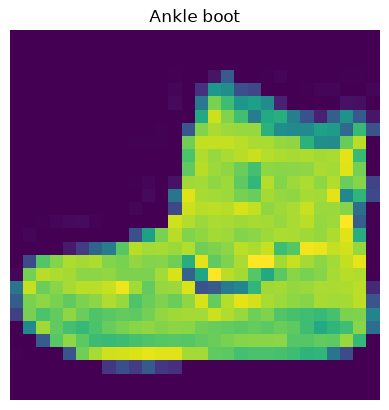

In [24]:
plt.imshow(image.squeeze(0))
plt.title(train_data.classes[label])
plt.axis("off")


We can turn the image into grayscale using the `cmap` parameter of `plt.imshow()`.

<a id="practice-task-8"></a>

**Your task 8 — write in the next code cell**

Plot that image again using cmap='gray'.

**Inspect when finished:** Explain the display difference from the default color map.


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

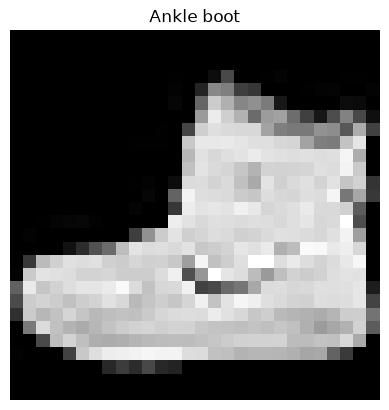

In [25]:
plt.imshow(image.squeeze(0), cmap='gray')
plt.title(train_data.classes[label])
plt.axis("off")

Beautiful, well as beautiful as a pixelated grayscale ankle boot can get.

Let's view a few more.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `plt.figure(figsize=(width,height))` | Creates a plotting canvas; figsize uses inches. Later plotting calls add series to the current axes. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
plt.figure(figsize=(6, 4))
```

<a id="practice-task-9"></a>

**Your task 9 — write in the next code cell**

Seed 42, select 16 random training examples, and plot a four-by-four grid with class-name titles.

**Inspect when finished:** Every image has its own matching label; axes do not obscure the images.


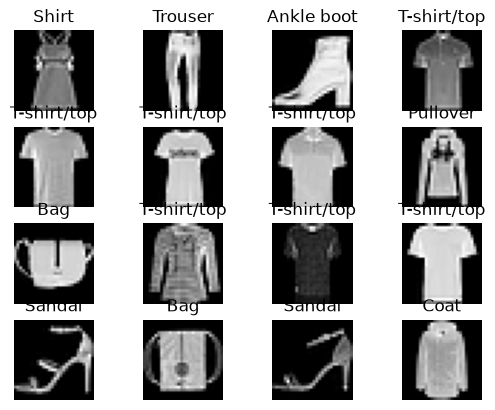

In [27]:
import random

random.seed(42)
indices = random.sample(range(len(train_data)), 16)

rand = random.seed(42)
for i, index in enumerate(indices):
    image, label = train_data[index]
    plt.subplot(4, 4, i + 1)
    plt.imshow(image.squeeze(0), cmap="gray")
    plt.title(class_names[label])
    plt.axis("off")

Hmmm, this dataset doesn't look too aesthetic.

But the principles we're going to learn on how to build a model for it will be similar across a wide range of computer vision problems.

In essence, taking pixel values and building a model to find patterns in them to use on future pixel values.

Plus, even for this small dataset (yes, even 60,000 images in deep learning is considered quite small), could you write a program to classify each one of them?

You probably could.

But I think coding a model in PyTorch would be faster.

> **Question:** Do you think the above data can be modeled with only straight (linear) lines? Or do you think you'd also need non-straight (non-linear) lines?

## 2. Prepare DataLoader

Now we've got a dataset ready to go.

The next step is to prepare it with a [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) or `DataLoader` for short.

The `DataLoader` does what you think it might do.

It helps load data into a model.

For training and for inference.

It turns a large `Dataset` into a Python iterable of smaller chunks.

These smaller chunks are called **batches** or **mini-batches** and can be set by the `batch_size` parameter.

Why do this?

Because it's more computationally efficient.

In an ideal world you could do the forward pass and backward pass across all of your data at once.

But once you start using really large datasets, unless you've got infinite computing power, it's easier to break them up into batches.

It also gives your model more opportunities to improve.

With **mini-batches** (small portions of the data), gradient descent is performed more often per epoch (once per mini-batch rather than once per epoch).

What's a good batch size?

[32 is a good place to start](https://twitter.com/ylecun/status/989610208497360896?s=20&t=N96J_jotN--PYuJk2WcjMw) for a fair amount of problems.

But since this is a value you can set (a **hyperparameter**) you can try all different kinds of values, though generally powers of 2 are used most often (e.g. 32, 64, 128, 256, 512).

![an example of what a batched dataset looks like](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-batching-fashionmnist.png)
*Batching FashionMNIST with a batch size of 32 and shuffle turned on. A similar batching process will occur for other datasets but will differ depending on the batch size.*

Let's create `DataLoader`'s for our training and test sets. 

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `DataLoader(dataset, batch_size=1, shuffle=False, num_workers=0)` | Batches dataset items. For this Mac notebook use num_workers=0; shuffle training only. len(loader) is batch count. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
loader = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=0)
```

<a id="practice-task-10"></a>

**Your task 10 — write in the next code cell**

Create train_dataloader and test_dataloader with batch size 32. Shuffle only training data; use num_workers=0 for the notebook on your Mac.

**Inspect when finished:** Iterating returns image and label batches rather than single examples.


In [29]:
train_dataloader = DataLoader(dataset=train_data, batch_size=32, shuffle=True)
test_dataloader = DataLoader(dataset=test_data, batch_size=32, shuffle=True)

<a id="practice-task-11"></a>

**Your task 11 — write in the next code cell**

Fetch one training batch and display feature and target shapes.

**Inspect when finished:** A full image batch has shape $(32,1,28,28)$ and labels have shape $(32,)$.


In [35]:
images, labels = next(iter(train_dataloader))

print(images.shape)
print(labels.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


And we can see that the data remains unchanged by checking a single sample. 

<a id="practice-task-12"></a>

**Your task 12 — write in the next code cell**

Plot one random image from the fetched batch with its class name.

**Inspect when finished:** Indexing the batch gives one image, not a whole batch grid.


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

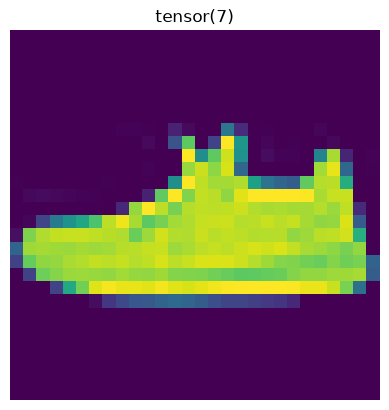

In [37]:
sample = random.randint(0,32)
plt.imshow(images[sample].squeeze(0))
plt.title(labels[sample])
plt.axis("off")

## 3. Model 0: Build a baseline model

Data loaded and prepared!

Time to build a **baseline model** by subclassing `nn.Module`.

A **baseline model** is one of the simplest models you can imagine.

You use the baseline as a starting point and try to improve upon it with subsequent, more complicated models.

Our baseline will consist of two [`nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) layers.

We've done this in a previous section but there's going to be one slight difference.

Because we're working with image data, we're going to use a different layer to start things off.

And that's the [`nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html) layer.

`nn.Flatten()` compresses the dimensions of a tensor into a single vector.

This is easier to understand when you see it.

### Learn first: A model consumes features; images have extra axes (Tasks 13–24)
`nn.Flatten(start_dim=1)` preserves the batch axis and collapses all remaining dimensions into features. The default start_dim is one. Thus $(N,1,28,28)$ becomes $(N,784)$. Flattening an **unbatched** image with the same default does not mean the same thing: inspect shapes before guessing.

Use Linear and Sequential exactly as in Chapter 02, with 784 input features and ten output logits. CrossEntropyLoss still takes int64 class labels, not one-hot vectors.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `nn.Flatten(start_dim=1, end_dim=-1)` | Collapses the selected axes. Default preserves the batch axis; use start_dim=2 when preserving batch and embedding axes. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
nn.Flatten()(torch.randn(2, 1, 4, 4))
```

<a id="practice-task-13"></a>

**Your task 13 — write in the next code cell**

Create nn.Flatten and apply it to one batched image. Compare input/output shapes.

**Inspect when finished:** The image's channel, height, and width become 784 features while batch size stays intact.


The `nn.Flatten()` layer took our shape from `[color_channels, height, width]` to `[color_channels, height*width]`.

Why do this?

Because we've now turned our pixel data from height and width dimensions into one long **feature vector**.

And `nn.Linear()` layers like their inputs to be in the form of feature vectors.

Let's create our first model using `nn.Flatten()` as the first layer. 

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `nn.Sequential(layer1, layer2, ...)` | Registers and executes child modules in order. Adjacent input/output feature sizes must agree. |
| `nn.Linear(in_features, out_features, bias=True)` | Creates an affine layer. Float input ending in in_features becomes output ending in out_features; parameters initialize at construction. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
nn.Sequential(nn.Linear(3, 4), nn.ReLU(), nn.Linear(4, 2))
nn.Linear(3, 2)(torch.randn(4, 3))
```

<a id="practice-task-14"></a>

**Your task 14 — write in the next code cell**

Define FashionMNISTModelV0 with an nn.Sequential containing Flatten, Linear from input_shape to hidden_units, and Linear from hidden_units to output_shape. Implement forward.

**Inspect when finished:** This baseline has no nonlinear activation and returns one logit per class.


Wonderful!

We've got a baseline model class we can use, now let's instantiate a model.

We'll need to set the following parameters:
* `input_shape=784` - this is how many features you've got going in the model, in our case, it's one for every pixel in the target image (28 pixels high by 28 pixels wide = 784 features).
* `hidden_units=10` - number of units/neurons in the hidden layer(s), this number could be whatever you want but to keep the model small we'll start with `10`.
* `output_shape=len(class_names)` - since we're working with a multi-class classification problem, we need an output neuron per class in our dataset.

Let's create an instance of our model and send to the CPU for now (we'll run a small test for running `model_0` on CPU vs. a similar model on GPU soon).

<a id="practice-task-15"></a>

**Your task 15 — write in the next code cell**

Seed 42; instantiate model_0 with input_shape=784, hidden_units=10, output_shape=10. Run a dummy image batch through it.

**Inspect when finished:** The output shape is $(N,10)$.


### 3.1 Setup loss, optimizer and evaluation metrics

Since we're working on a classification problem, let's bring in our [`helper_functions.py` script](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/helper_functions.py) and subsequently the `accuracy_fn()` we defined in [notebook 02](https://www.learnpytorch.io/02_pytorch_classification/).

> **Note:** Rather than importing and using our own accuracy function or evaluation metric(s), you could import various evaluation metrics from the [TorchMetrics package](https://torchmetrics.readthedocs.io/en/latest/).

<a id="practice-task-16"></a>

**Your task 16 — write in the next code cell**

Import accuracy_fn from helper_functions; download the upstream helper file only if it is missing.

**Inspect when finished:** Reusable metric code is available without creating a duplicate repository.

**Source files for this task:**

- [helper_functions.py](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py)


### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `nn.CrossEntropyLoss(label_smoothing=0.0)` | For these tasks: raw float logits $(N,C)$ and int64 class-index targets $(N,)$. Do not apply softmax before this loss. |
| `torch.optim.SGD(params, lr=...)` | params must reference this model's registered parameters. zero_grad clears gradients; step updates parameters from gradients computed by backward. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
criterion = nn.CrossEntropyLoss()
torch.optim.SGD(model.parameters(), lr=0.01)
```

<a id="practice-task-17"></a>

**Your task 17 — write in the next code cell**

Create CrossEntropyLoss and SGD with learning rate 0.1 for model_0.

**Inspect when finished:** The loss accepts logits and integer targets.


### 3.2 Creating a function to time our experiments

Loss function and optimizer ready!

It's time to start training a model.

But how about we do a little experiment while we train.

I mean, let's make a timing function to measure the time it takes our model to train on CPU versus using a GPU.

We'll train this model on the CPU but the next one on the GPU and see what happens.

Our timing function will import the [`timeit.default_timer()` function](https://docs.python.org/3/library/timeit.html#timeit.default_timer) from the Python [`timeit` module](https://docs.python.org/3/library/timeit.html).

<a id="practice-task-18"></a>

**Your task 18 — write in the next code cell**

Define print_train_time(start, end, device) to print and return elapsed seconds. Import timeit's default_timer.

**Inspect when finished:** The function returns a numeric duration you can store for model comparisons.


### 3.3 Creating a training loop and training a model on batches of data

Beautiful!

Looks like we've got all of the pieces of the puzzle ready to go, a timer, a loss function, an optimizer, a model and most importantly, some data.

Let's now create a training loop and a testing loop to train and evaluate our model.

We'll be using the same steps as the previous notebook(s), though since our data is now in batch form, we'll add another loop to loop through our data batches.

Our data batches are contained within our `DataLoader`s, `train_dataloader` and `test_dataloader` for the training and test data splits respectively.

A batch is `BATCH_SIZE` samples of `X` (features) and `y` (labels), since we're using `BATCH_SIZE=32`, our batches have 32 samples of images and targets.

And since we're computing on batches of data, our loss and evaluation metrics will be calculated **per batch** rather than across the whole dataset.

This means we'll have to divide our loss and accuracy values by the number of batches in each dataset's respective dataloader. 

Let's step through it: 
1. Loop through epochs.
2. Loop through training batches, perform training steps, calculate the train loss *per batch*.
3. Loop through testing batches, perform testing steps, calculate the test loss *per batch*.
4. Print out what's happening.
5. Time it all (for fun).

A fair few steps but...

...if in doubt, code it out. 

### Learn first: Minibatch training helpers (Tasks 19–29)
An epoch now contains several optimizer updates, one per training batch:

1. Enter train mode, loop over `(X_batch,y_batch)`, move both to device.
2. Forward, loss, zero gradients, backward, optimizer step for each batch.
3. Accumulate detached numeric loss and accuracy; average using the method stated in the task.
4. Evaluate test batches in eval/inference mode without updates.

A `train_step` helper performs one whole training epoch in this course, despite its name. Give it `model`, loader, loss, optimizer, and device explicitly. A `test_step` helper has no optimizer. Return numbers so the outer loop can record them. Keep accuracy units consistent; these FashionMNIST tasks use percentages.

`timer()` from timeit returns a time reading; subtract the before reading from the after reading for elapsed seconds. GPU operations can be asynchronous, so simple host timing is only an approximate comparison unless you synchronize. The core task here is learning batching, not establishing a hardware benchmark.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `torch.inference_mode()` | Disables autograd tracking in its block for inference. Use model.eval() separately to change Dropout/normalization behavior. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
with torch.inference_mode(): ...
```

<a id="practice-task-19"></a>

**Your task 19 — write in the next code cell**

Train model_0 on CPU for three epochs using all training batches. Compute batch loss/accuracy, update parameters with the five training steps, then evaluate all test batches in inference mode. Average each metric over batches and time the training.

**Inspect when finished:** Save total_train_time_model_0; epoch metrics reflect all batches rather than only the final batch.


Nice! Looks like our baseline model did fairly well.

It didn't take too long to train either, even just on the CPU, I wonder if it'll speed up on the GPU?

Let's write some code to evaluate our model.

## 4. Make predictions and get Model 0 results

Since we're going to be building a few models, it's a good idea to write some code to evaluate them all in similar ways.

Namely, let's create a function that takes in a trained model, a `DataLoader`, a loss function and an accuracy function.

The function will use the model to make predictions on the data in the `DataLoader` and then we can evaluate those predictions using the loss function and accuracy function.

<a id="practice-task-20"></a>

**Your task 20 — write in the next code cell**

Define eval_model(model, data_loader, loss_fn, accuracy_fn) for the CPU baseline. Evaluate without gradients and return model_name, model_loss, and model_acc in a dictionary. Save model_0_results.

**Inspect when finished:** This first version is CPU-only; you will add device handling later.


Looking good!

We can use this dictionary to compare the baseline model results to other models later on.

## 5. Setup device agnostic-code (for using a GPU if there is one)
We've seen how long it takes to train ma PyTorch model on 60,000 samples on CPU.

> **Note:** Model training time is dependent on hardware used. Generally, more processors means faster training and smaller models on smaller datasets will often train faster than large models and large datasets.

Now let's setup some [device-agnostic code](https://pytorch.org/docs/stable/notes/cuda.html#best-practices) for our models and data to run on GPU if it's available.

If you're running this notebook on Google Colab, and you don't have a GPU turned on yet, it's now time to turn one on via `Runtime -> Change runtime type -> Hardware accelerator -> GPU`. If you do this, your runtime will likely reset and you'll have to run all of the cells above by going `Runtime -> Run before`.

<a id="practice-task-21"></a>

**Your task 21 — write in the next code cell**

Choose CUDA, then MPS, then CPU as device.

**Inspect when finished:** CPU remains a valid choice; accelerated hardware is not required to complete the lesson.


Beautiful!

Let's build another model.

## 6. Model 1: Building a better model with non-linearity

We learned about [the power of non-linearity in notebook 02](https://www.learnpytorch.io/02_pytorch_classification/#6-the-missing-piece-non-linearity).

Seeing the data we've been working with, do you think it needs non-linear functions?

And remember, linear means straight and non-linear means non-straight.

Let's find out.

We'll do so by recreating a similar model to before, except this time we'll put non-linear functions (`nn.ReLU()`) in between each linear layer.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `nn.ReLU(inplace=False)` | Applies an element-wise nonlinearity; input/output shape is unchanged. Has no learned parameters. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
nn.ReLU()(torch.tensor([-2.0, 1.0]))
```

<a id="practice-task-22"></a>

**Your task 22 — write in the next code cell**

Define FashionMNISTModelV1 with Flatten, Linear, ReLU, Linear, and ReLU, matching the original baseline's widths.

**Inspect when finished:** This model introduces nonlinear activations; it still returns ten scores per example.


That looks good.

Now let's instantiate it with the same settings we used before.

We'll need `input_shape=784` (equal to the number of features of our image data), `hidden_units=10` (starting small and the same as our baseline model) and `output_shape=len(class_names)` (one output unit per class).

> **Note:** Notice how we kept most of the settings of our model the same except for one change: adding non-linear layers. This is a standard practice for running a series of machine learning experiments, change one thing and see what happens, then do it again, again, again.

<a id="practice-task-23"></a>

**Your task 23 — write in the next code cell**

Seed 42, instantiate model_1 with the same feature/class counts, move it to device, and inspect its first parameter device.

**Inspect when finished:** Model parameters live on your selected device.


### 6.1 Setup loss, optimizer and evaluation metrics

As usual, we'll setup a loss function, an optimizer and an evaluation metric (we could do multiple evaluation metrics but we'll stick with accuracy for now).

<a id="practice-task-24"></a>

**Your task 24 — write in the next code cell**

Create a fresh CrossEntropyLoss and SGD optimizer with learning rate 0.1 for model_1.

**Inspect when finished:** The optimizer is tied to model_1 rather than model_0.


### 6.2 Functionizing training and test loops

So far we've been writing train and test loops over and over. 

Let's write them again but this time we'll put them in functions so they can be called again and again.

And because we're using device-agnostic code now, we'll be sure to call `.to(device)` on our feature (`X`) and target (`y`) tensors.

For the training loop we'll create a function called `train_step()` which takes in a model, a `DataLoader` a loss function and an optimizer.

The testing loop will be similar but it'll be called `test_step()` and it'll take in a model, a `DataLoader`, a loss function and an evaluation function.

> **Note:** Since these are functions, you can customize them in any way you like. What we're making here can be considered barebones training and testing functions for our specific classification use case.

<a id="practice-task-25"></a>

**Your task 25 — write in the next code cell**

Define train_step and test_step helpers taking model, data_loader, loss_fn, accuracy_fn, and device; train_step also takes optimizer. Move each batch to device, average metrics across batches, and use eval/inference mode only in test_step.

**Inspect when finished:** Both helpers return numeric loss and percentage accuracy; only train_step updates parameters.


Woohoo!

Now we've got some functions for training and testing our model, let's run them.

We'll do so inside another loop for each epoch.

That way, for each epoch, we're going through a training step and a testing step.

> **Note:** You can customize how often you do a testing step. Sometimes people do them every five epochs or 10 epochs or in our case, every epoch.

Let's also time things to see how long our code takes to run on the GPU.

<a id="practice-task-26"></a>

**Your task 26 — write in the next code cell**

Train model_1 for three epochs using your helpers and measure total_train_time_model_1.

**Inspect when finished:** Save the timing and record train/test metrics per epoch.


Excellent!

Our model trained but the training time took longer?

> **Note:** The training time on CUDA vs CPU will depend largely on the quality of the CPU/GPU you're using. Read on for a more explained answer.

> **Question:** "I used a GPU but my model didn't train faster, why might that be?"
>
> **Answer:** Well, one reason could be because your dataset and model are both so small (like the dataset and model we're working with) the benefits of using a GPU are outweighed by the time it actually takes to transfer the data there.
> 
> There's a small bottleneck between copying data from the CPU memory (default) to the GPU memory.
>
> So for smaller models and datasets, the CPU might actually be the optimal place to compute on.
>
> But for larger datasets and models, the speed of computing the GPU can offer usually far outweighs the cost of getting the data there.
>
> However, this is largely dependent on the hardware you're using. With practice, you will get used to where the best place to train your models is. 

Let's evaluate our trained `model_1` using our `eval_model()` function and see how it went.

<a id="practice-task-27"></a>

**Your task 27 — write in the next code cell**

Try your earlier CPU-only eval_model on device-resident model_1. On MPS/CUDA, read the expected device-mismatch error; on CPU, explain why it succeeds.

**Inspect when finished:** Identify that the evaluator must also move its input batches.


Oh no! 

It looks like our `eval_model()` function errors out with:

> `RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_addmm)`

It's because we've setup our data and model to use device-agnostic code but not our evaluation function.

How about we fix that by passing a target `device` parameter to our `eval_model()` function?

Then we'll try calculating the results again.

<a id="practice-task-28"></a>

**Your task 28 — write in the next code cell**

Update eval_model to accept device, move both model and batches appropriately, and evaluate model_1 into model_1_results.

**Inspect when finished:** The evaluator now works for CPU, MPS, or CUDA.


<a id="practice-task-29"></a>

**Your task 29 — write in the next code cell**

Display model_0_results beside model_1_results.

**Inspect when finished:** Compare accuracy and loss; do not infer speed solely from hardware names.


Woah, in this case, it looks like adding non-linearities to our model made it perform worse than the baseline.

That's a thing to note in machine learning, sometimes the thing you thought should work doesn't. 

And then the thing you thought might not work does.

It's part science, part art.

From the looks of things, it seems like our model is **overfitting** on the training data.

Overfitting means our model is learning the training data well but those patterns aren't generalizing to the testing data.

Two of the main ways to fix overfitting include:
1. Using a smaller or different model (some models fit certain kinds of data better than others).
2. Using a larger dataset (the more data, the more chance a model has to learn generalizable patterns).

There are more, but I'm going to leave that as a challenge for you to explore.

Try searching online, "ways to prevent overfitting in machine learning" and see what comes up.

In the meantime, let's take a look at number 1: using a different model.

## 7. Model 2: Building a Convolutional Neural Network (CNN)

Alright, time to step things up a notch.

It's time to create a [Convolutional Neural Network](https://en.wikipedia.org/wiki/Convolutional_neural_network) (CNN or ConvNet).

CNN's are known for their capabilities to find patterns in visual data.

And since we're dealing with visual data, let's see if using a CNN model can improve upon our baseline.

The CNN model we're going to be using is known as TinyVGG from the [CNN Explainer](https://poloclub.github.io/cnn-explainer/) website.

It follows the typical structure of a convolutional neural network:

`Input layer -> [Convolutional layer -> activation layer -> pooling layer] -> Output layer`

Where the contents of `[Convolutional layer -> activation layer -> pooling layer]` can be upscaled and repeated multiple times, depending on requirements. 

### What model should I use?

> **Question:** Wait, you say CNN's are good for images, are there any other model types I should be aware of?

Good question.

This table is a good general guide for which model to use (though there are exceptions).

| **Problem type** | **Model to use (generally)** | **Code example** |
| ----- | ----- | ----- |
| Structured data (Excel spreadsheets, row and column data) | Gradient boosted models, Random Forests, XGBoost | [`sklearn.ensemble`](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.ensemble), [XGBoost library](https://xgboost.readthedocs.io/en/stable/) |
| Unstructured data (images, audio, language) | Convolutional Neural Networks, Transformers | [`torchvision.models`](https://pytorch.org/vision/stable/models.html), [HuggingFace Transformers](https://huggingface.co/docs/transformers/index) | 

> **Note:** The table above is only for reference, the model you end up using will be highly dependent on the problem you're working on and the constraints you have (amount of data, latency requirements).

Enough talking about models, let's now build a CNN that replicates the model on the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

![TinyVGG architecture, as setup by CNN explainer website](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-cnn-explainer-model.png)

To do so, we'll leverage the [`nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and [`nn.MaxPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) layers from `torch.nn`.


### Learn first: Convolution and pooling (Tasks 30–42)
`nn.Conv2d(in_channels,out_channels,kernel_size,stride=1,padding=0)` creates a learnable convolution layer. The first two arguments describe **channels**, not image height/width. A kernel slides over spatial dimensions and produces out_channels feature maps. `padding` adds border positions; `stride` is movement between applications.

```python
example_conv = nn.Conv2d(1, 4, kernel_size=3, padding=1)
example_pool = nn.MaxPool2d(kernel_size=2)
feature_maps = example_conv(torch.randn(2, 1, 8, 8))
print(feature_maps.shape)            # (2, 4, 8, 8)
print(example_pool(feature_maps).shape)  # (2, 4, 4, 4)
```

Pool layers select a maximum in each spatial window and have no learned weights here. ReLU changes values but not shape. Before defining a final Linear layer, work out or print the flattened feature count after your convolution/pooling sequence.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0)` | Consumes channel-first float images $(N,C,H,W)$; out_channels is feature-map count, not image width. Kernel/stride/padding determine spatial output size. |
| `nn.MaxPool2d(kernel_size, stride=None)` | Selects window maxima, preserving channels and shrinking spatial axes. Default stride equals kernel_size; no learned parameters. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
nn.Conv2d(1, 4, 3, padding=1)(torch.randn(2, 1, 8, 8))
nn.MaxPool2d(2)(torch.randn(2, 4, 8, 8))
```

<a id="practice-task-30"></a>

**Your task 30 — write in the next code cell**

Define FashionMNISTModelV2 as a TinyVGG CNN: two blocks of Conv2d, ReLU, Conv2d, ReLU, MaxPool2d, followed by Flatten and Linear to ten classes. Use one input channel, hidden width 10, kernel size 3, padding 1, and pooling size 2. Instantiate model_2 on device.

**Inspect when finished:** For a 28-by-28 input, two pooling stages leave a 7-by-7 feature map; the classifier takes 490 features.


Nice!

Our biggest model yet!

What we've done is a common practice in machine learning.

Find a model architecture somewhere and replicate it with code. 

### 7.1 Stepping through `nn.Conv2d()`

We could start using our model above and see what happens but let's first step through the two new layers we've added:
* [`nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), also known as a convolutional layer.
* [`nn.MaxPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html), also known as a max pooling layer.

> **Question:** What does the "2d" in `nn.Conv2d()` stand for?
>
> The 2d is for 2-dimensional data. As in, our images have two dimensions: height and width. Yes, there's color channel dimension but each of the color channel dimensions have two dimensions too: height and width.
>
> For other dimensional data (such as 1D for text or 3D for 3D objects) there's also `nn.Conv1d()` and `nn.Conv3d()`. 

To test the layers out, let's create some toy data just like the data used on CNN Explainer.

<a id="practice-task-31"></a>

**Your task 31 — write in the next code cell**

Create a random image batch with shape $(32,3,64,64)$ and select one test_image.

**Inspect when finished:** This separate three-channel example is for exploring convolution shapes, not FashionMNIST training.


Let's create an example `nn.Conv2d()` with various parameters:
* `in_channels` (int) - Number of channels in the input image.
* `out_channels` (int) - Number of channels produced by the convolution.
* `kernel_size` (int or tuple) - Size of the convolving kernel/filter.
* `stride` (int or tuple, optional) - How big of a step the convolving kernel takes at a time. Default: 1.
* `padding` (int, tuple, str) - Padding added to all four sides of input. Default: 0.

![example of going through the different parameters of a Conv2d layer](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-conv2d-layer.gif)

*Example of what happens when you change the hyperparameters of a `nn.Conv2d()` layer.*

<a id="practice-task-32"></a>

**Your task 32 — write in the next code cell**

Create conv_layer as Conv2d with 3 input channels, 10 output channels, kernel size 3, stride 1, padding 0.

**Inspect when finished:** It expects a three-channel input and shrinks each spatial dimension by two.


If we try to pass a single image in, we get a shape mismatch error:

> `RuntimeError: Expected 4-dimensional input for 4-dimensional weight [10, 3, 3, 3], but got 3-dimensional input of size [3, 64, 64] instead`
>
> **Note:** If you're running PyTorch 1.11.0+, this error won't occur.

This is because our `nn.Conv2d()` layer expects a 4-dimensional tensor as input with size `(N, C, H, W)` or `[batch_size, color_channels, height, width]`.

Right now our single image `test_image` only has a shape of `[color_channels, height, width]` or `[3, 64, 64]`.

We can fix this for a single image using `test_image.unsqueeze(dim=0)` to add an extra dimension for `N`.

<a id="practice-task-33"></a>

**Your task 33 — write in the next code cell**

Add a batch dimension to test_image and inspect its shape.

**Inspect when finished:** A single image now has batch size one.


<a id="practice-task-34"></a>

**Your task 34 — write in the next code cell**

Pass the batched image through conv_layer and inspect output shape.

**Inspect when finished:** Ten output feature maps are produced; channel count matches out_channels.


Hmm, notice what happens to our shape (the same shape as the first layer of TinyVGG on [CNN Explainer](https://poloclub.github.io/cnn-explainer/)), we get different channel sizes as well as different pixel sizes.

What if we changed the values of `conv_layer`?

<a id="practice-task-35"></a>

**Your task 35 — write in the next code cell**

Create conv_layer_2 with the same channel counts and kernel size but padding 1; apply it to the image. Try changing stride or padding and record the shape changes.

**Inspect when finished:** Padding 1 preserves spatial size when kernel size is 3 and stride is 1.


Woah, we get another shape change.

Now our image is of shape `[1, 10, 30, 30]` (it will be different if you use different values) or `[batch_size=1, color_channels=10, height=30, width=30]`.

What's going on here?

Behind the scenes, our `nn.Conv2d()` is compressing the information stored in the image.

It does this by performing operations on the input (our test image) against its internal parameters.

The goal of this is similar to all of the other neural networks we've been building.

Data goes in and the layers try to update their internal parameters (patterns) to lower the loss function thanks to some help of the optimizer.

The only difference is *how* the different layers calculate their parameter updates or in PyTorch terms, the operation present in the layer `forward()` method.

If we check out our `conv_layer_2.state_dict()` we'll find a similar weight and bias setup as we've seen before.

<a id="practice-task-36"></a>

**Your task 36 — write in the next code cell**

Display conv_layer_2.state_dict().

**Inspect when finished:** Identify weight and bias entries without treating the entire model object as a tensor.


Look at that! A bunch of random numbers for a weight and bias tensor.

The shapes of these are manipulated by the inputs we passed to `nn.Conv2d()` when we set it up.

Let's check them out.

<a id="practice-task-37"></a>

**Your task 37 — write in the next code cell**

Inspect conv_layer_2.weight.shape and bias.shape. Explain how input/output channels and kernel size determine them.

**Inspect when finished:** Weight shape is $(10,3,3,3)$ and bias shape is $(10,)$ for the stated settings.


> **Question:** What should we set the parameters of our `nn.Conv2d()` layers?
>
> That's a good one. But similar to many other things in machine learning, the values of these aren't set in stone (and recall, because these values are ones we can set ourselves, they're referred to as "**hyperparameters**"). 
>
> The best way to find out is to try out different values and see how they effect your model's performance.
>
> Or even better, find a working example on a problem similar to yours (like we've done with TinyVGG) and copy it. 

We're working with a different of layer here to what we've seen before.

But the premise remains the same: start with random numbers and update them to better represent the data.

### 7.2 Stepping through `nn.MaxPool2d()`
Now let's check out what happens when we move data through `nn.MaxPool2d()`.

<a id="practice-task-38"></a>

**Your task 38 — write in the next code cell**

Apply conv_layer then MaxPool2d with kernel size 2 to your batched image. Print shapes before convolution, after convolution, and after pooling.

**Inspect when finished:** Pooling reduces spatial dimensions without changing channel count.


Notice the change in the shapes of what's happening in and out of a `nn.MaxPool2d()` layer.

The `kernel_size` of the `nn.MaxPool2d()` layer will affect the size of the output shape.

In our case, the shape halves from a `62x62` image to `31x31` image.

Let's see this work with a smaller tensor.

<a id="practice-task-39"></a>

**Your task 39 — write in the next code cell**

Create a small random tensor of shape $(1,1,2,2)$ and apply MaxPool2d with kernel size 2. Display values before/after.

**Inspect when finished:** The pooled output contains the maximum of the four inputs.


Notice the final two dimensions between `random_tensor` and `max_pool_tensor`, they go from `[2, 2]` to `[1, 1]`.

In essence, they get halved.

And the change would be different for different values of `kernel_size` for `nn.MaxPool2d()`.

Also notice the value leftover in `max_pool_tensor` is the **maximum** value from `random_tensor`.

What's happening here?

This is another important piece of the puzzle of neural networks.

Essentially, **every layer in a neural network is trying to compress data from higher dimensional space to lower dimensional space**. 

In other words, take a lot of numbers (raw data) and learn patterns in those numbers, patterns that are predictive whilst also being *smaller* in size than the original values.

From an artificial intelligence perspective, you could consider the whole goal of a neural network to *compress* information.

![each layer of a neural network compresses the original input data into a smaller representation that is (hopefully) capable of making predictions on future input data](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-conv-net-as-compression.png)

This means, that from the point of view of a neural network, intelligence is compression.

This is the idea of the use of a `nn.MaxPool2d()` layer: take the maximum value from a portion of a tensor and disregard the rest.

In essence, lowering the dimensionality of a tensor whilst still retaining a (hopefully) significant portion of the information.

It is the same story for a `nn.Conv2d()` layer.

Except instead of just taking the maximum, the `nn.Conv2d()` performs a convolutional operation on the data (see this in action on the [CNN Explainer webpage](https://poloclub.github.io/cnn-explainer/)).

> **Exercise:** What do you think the [`nn.AvgPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html) layer does? Try making a random tensor like we did above and passing it through. Check the input and output shapes as well as the input and output values.

> **Extra-curriculum:** Lookup "most common convolutional neural networks", what architectures do you find? Are any of them contained within the [`torchvision.models`](https://pytorch.org/vision/stable/models.html) library? What do you think you could do with these?

### 7.3 Setup a loss function and optimizer for `model_2`

We've stepped through the layers in our first CNN enough.

But remember, if something still isn't clear, try starting small.

Pick a single layer of a model, pass some data through it and see what happens.

Now it's time to move forward and get to training!

Let's setup a loss function and an optimizer.

We'll use the functions as before, `nn.CrossEntropyLoss()` as the loss function (since we're working with multi-class classification data).

And `torch.optim.SGD()` as the optimizer to optimize `model_2.parameters()` with a learning rate of `0.1`.

<a id="practice-task-40"></a>

**Your task 40 — write in the next code cell**

Create CrossEntropyLoss and SGD with learning rate 0.1 for model_2.

**Inspect when finished:** The optimizer references the CNN's parameters.


### 7.4 Training and testing `model_2` using our training and test functions

Loss and optimizer ready!

Time to train and test.

We'll use our `train_step()` and `test_step()` functions we created before.

We'll also measure the time to compare it to our other models.

<a id="practice-task-41"></a>

**Your task 41 — write in the next code cell**

Train model_2 for three epochs with your device-aware train_step/test_step and time it.

**Inspect when finished:** Save total_train_time_model_2 and compare test performance with the previous models.


Woah! Looks like the convolutional and max pooling layers helped improve performance a little.

Let's evaluate `model_2`'s results with our `eval_model()` function.

<a id="practice-task-42"></a>

**Your task 42 — write in the next code cell**

Evaluate the trained CNN using eval_model and save model_2_results.

**Inspect when finished:** The result dictionary has the same keys as the earlier model results.


## 8. Compare model results and training time

We've trained three different models.

1. `model_0` - our baseline model with two `nn.Linear()` layers.
2. `model_1` - the same setup as our baseline model except with `nn.ReLU()` layers in between the `nn.Linear()` layers.
3. `model_2` - our first CNN model that mimics the TinyVGG architecture on the CNN Explainer website.

This is a regular practice in machine learning.

Building multiple models and performing multiple training experiments to see which performs best.

Let's combine our model results dictionaries into a DataFrame and find out.

### Learn first: Interpret results, then save (Tasks 43–61)
`torch.softmax(logits,dim=1)` produces class probabilities; argmax selects class index. Pair predictions with original labels and class_names to identify errors. A confusion matrix counts true/predicted label pairs; the axes must be labelled before interpreting off-diagonal cells.

`pd.DataFrame([result_dict_a,result_dict_b])` creates one comparison row per model. A named Series supports plotting with `.plot(kind='barh')`. You can reuse matplotlib line plots for histories.

Save/reload with the Chapter 01 state_dict workflow. The reconstructed CNN must have exactly the same layer/parameter shapes as the checkpoint.

References: [Dataset/DataLoader tutorial](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html), [Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `pd.DataFrame(data, columns=None, ...)` | Dictionary of arrays gives one column per key; list of dictionaries gives one record per row. head previews; value_counts counts a selected column. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
pd.DataFrame({"feature": [1, 2], "label": [0, 1]})
```

<a id="practice-task-43"></a>

**Your task 43 — write in the next code cell**

Create a pandas DataFrame compare_results from the three result dictionaries.

**Inspect when finished:** Each model occupies one row with comparable metric columns.


Nice!

We can add the training time values too.

<a id="practice-task-44"></a>

**Your task 44 — write in the next code cell**

Add a training_time column using the three recorded durations.

**Inspect when finished:** Each duration is aligned with the correct model row.


It looks like our CNN (`FashionMNISTModelV2`) model performed the best (lowest loss, highest accuracy) but had the longest training time.

And our baseline model (`FashionMNISTModelV0`) performed better than `model_1` (`FashionMNISTModelV1`).

### Performance-speed tradeoff

Something to be aware of in machine learning is the **performance-speed** tradeoff.

Generally, you get better performance out of a larger, more complex model (like we did with `model_2`).

However, this performance increase often comes at a sacrifice of training speed and inference speed.

> **Note:** The training times you get will be very dependent on the hardware you use. 
>
> Generally, the more CPU cores you have, the faster your models will train on CPU. And similar for GPUs.
> 
> Newer hardware (in terms of age) will also often train models faster due to incorporating technological advances.

How about we get visual?

<a id="practice-task-45"></a>

**Your task 45 — write in the next code cell**

Plot a horizontal bar chart of model_acc by model_name.

**Inspect when finished:** You can identify which model performed best on this particular run.


## 9. Make and evaluate random predictions with best model

Alright, we've compared our models to each other, let's further evaluate our best performing model, `model_2`.

To do so, let's create a function `make_predictions()` where we can pass the model and some data for it to predict on.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `torch.softmax(input, dim)` | Normalizes across dim. For logits $(N,C)$ use dim=1 so each sample's class probabilities sum to one. |
| `torch.stack(tensors, dim=0)` | Adds a new axis; all tensors must have identical shapes. dim selects where the new axis goes. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
torch.softmax(torch.randn(2, 3), dim=1)
torch.stack([torch.ones(3), torch.zeros(3)], dim=0)
```

<a id="practice-task-46"></a>

**Your task 46 — write in the next code cell**

Define make_predictions(model, data, device) to process a list of unbatched images in eval/inference mode, adding batch dimensions and applying softmax across classes. Return stacked CPU probability tensors.

**Inspect when finished:** For nine examples, return shape $(9,10)$; plotting code can consume the CPU results.


<a id="practice-task-47"></a>

**Your task 47 — write in the next code cell**

Use Python random.sample to choose nine test examples; store images in test_samples and labels in test_labels.

**Inspect when finished:** Each sample is paired with its original label.


<a id="practice-task-48"></a>

**Your task 48 — write in the next code cell**

Call make_predictions on model_2 and test_samples; store pred_probs and inspect the first two rows.

**Inspect when finished:** Each row has ten class probabilities that sum approximately to one.


And now we can use our `make_predictions()` function to predict on `test_samples`.

<a id="practice-task-49"></a>

**Your task 49 — write in the next code cell**

Repeat the preceding prediction call and compare its output.

**Inspect when finished:** With an unchanged model in evaluation mode, repeated predictions should match within tolerance.


Excellent!

And now we can go from prediction probabilities to prediction labels by taking the `torch.argmax()` of the output of the `torch.softmax()` activation function.

<a id="practice-task-50"></a>

**Your task 50 — write in the next code cell**

Convert pred_probs to pred_classes with argmax along the class dimension.

**Inspect when finished:** You get one integer prediction per sample.


<a id="practice-task-51"></a>

**Your task 51 — write in the next code cell**

Display test_labels and pred_classes together.

**Inspect when finished:** Predicted indices and ground-truth indices use the same class-name mapping.


Now our predicted classes are in the same format as our test labels, we can compare.

Since we're dealing with image data, let's stay true to the data explorer's motto. 

"Visualize, visualize, visualize!"

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `plt.subplot(nrows, ncols, index)` | Selects a position in the current figure; index starts at one. It does not select a data sample. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
plt.subplot(2, 2, 1)
```

<a id="practice-task-52"></a>

**Your task 52 — write in the next code cell**

Plot the nine sampled images in a grid. Title each with predicted and true class names; use a distinct title color for correct versus incorrect predictions.

**Inspect when finished:** You can inspect concrete model mistakes rather than only an aggregate accuracy.


Well, well, well, doesn't that look good!

Not bad for a couple dozen lines of PyTorch code!

## 10. Making a confusion matrix for further prediction evaluation

There are many [different evaluation metrics](https://www.learnpytorch.io/02_pytorch_classification/#9-more-classification-evaluation-metrics) we can use for classification problems. 

One of the most visual is a [confusion matrix](https://www.dataschool.io/simple-guide-to-confusion-matrix-terminology/).

A confusion matrix shows you where your classification model got confused between predictions and true labels.

To make a confusion matrix, we'll go through three steps:
1. Make predictions with our trained model, `model_2` (a confusion matrix compares predictions to true labels).
2. Make a confusion matrix using [`torchmetrics.ConfusionMatrix`](https://torchmetrics.readthedocs.io/en/latest/references/modules.html?highlight=confusion#confusionmatrix).
3. Plot the confusion matrix using [`mlxtend.plotting.plot_confusion_matrix()`](http://rasbt.github.io/mlxtend/user_guide/plotting/plot_confusion_matrix/).

Let's start by making predictions with our trained model.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `torch.cat(tensors, dim=0)` | Concatenates along an existing dimension. Other dimensions must match; unlike stack it does not add an axis. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
torch.cat([torch.ones(1, 2), torch.zeros(1, 2)], dim=0)
```

<a id="practice-task-53"></a>

**Your task 53 — write in the next code cell**

Iterate over the full test_dataloader in eval/inference mode, collect predicted class indices on CPU, and concatenate into y_pred_tensor.

**Inspect when finished:** Predictions follow test_data.targets order because testing is not shuffled.


Wonderful!

Now we've got predictions, let's go through steps 2 & 3:
2. Make a confusion matrix using [`torchmetrics.ConfusionMatrix`](https://torchmetrics.readthedocs.io/en/latest/references/modules.html?highlight=confusion#confusionmatrix).
3. Plot the confusion matrix using [`mlxtend.plotting.plot_confusion_matrix()`](http://rasbt.github.io/mlxtend/user_guide/plotting/plot_confusion_matrix/).

First we'll need to make sure we've got `torchmetrics` and `mlxtend` installed (these two libraries will help us make and visualize a confusion matrix).

> **Note:** If you're using Google Colab, the default version of `mlxtend` installed is 0.14.0 (as of March 2022), however, for the parameters of the `plot_confusion_matrix()` function we'd like use, we need 0.19.0 or higher. 

<a id="practice-task-54"></a>

**Your task 54 — write in the next code cell**

Import ConfusionMatrix from torchmetrics and plot_confusion_matrix from mlxtend.plotting. If either import fails, install that package with %pip and rerun.

**Inspect when finished:** These are optional visualization dependencies, not a reason to replace your PyTorch environment.


To plot the confusion matrix, we need to make sure we've got and [`mlxtend`](http://rasbt.github.io/mlxtend/) version of 0.19.0 or higher.

<a id="practice-task-55"></a>

**Your task 55 — write in the next code cell**

Import mlxtend and display its version.

**Inspect when finished:** This identifies the plotting library used in the next cell; no automatic version parsing or upgrades are needed.


`torchmetrics` and `mlxtend` installed, let's make a confusion matrix!

First we'll create a `torchmetrics.ConfusionMatrix` instance telling it how many classes we're dealing with by setting `num_classes=len(class_names)`.

Then we'll create a confusion matrix (in tensor format) by passing our instance our model's predictions (`preds=y_pred_tensor`) and targets (`target=test_data.targets`).

Finally we can plot our confusion matrix using the `plot_confusion_matrix()` function from `mlxtend.plotting`.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `ConfusionMatrix(task="multiclass", num_classes=C, ...)` | torchmetrics object counts true/predicted class combinations. Pass aligned integer predictions/targets on the same device and label plotted axes. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
metric = ConfusionMatrix(task="multiclass", num_classes=10)
```

<a id="practice-task-56"></a>

**Your task 56 — write in the next code cell**

Create a ten-class multiclass confusion matrix from y_pred_tensor and test_data.targets, then plot it with class names.

**Inspect when finished:** Diagonal entries are correct predictions; off-diagonal entries show confusions.


Woah! Doesn't that look good?

We can see our model does fairly well since most of the dark squares are down the diagonal from top left to bottom right (and ideal model will have only values in these squares and 0 everywhere else).

The model gets most "confused" on classes that are similar, for example predicting "Pullover" for images that are actually labelled "Shirt".

And the same for predicting "Shirt" for classes that are actually labelled "T-shirt/top".

This kind of information is often more helpful than a single accuracy metric because it tells use *where* a model is getting things wrong.

It also hints at *why* the model may be getting certain things wrong.

It's understandable the model sometimes predicts "Shirt" for images labelled "T-shirt/top".

We can use this kind of information to further inspect our models and data to see how it could be improved.

> **Exercise:** Use the trained `model_2` to make predictions on the test FashionMNIST dataset. Then plot some predictions where the model was wrong alongside what the label of the image should've been. After visualizing these predictions do you think it's more of a modelling error or a data error? As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?

## 11. Save and load best performing model

Let's finish this section off by saving and loading in our best performing model.

Recall from [notebook 01](https://www.learnpytorch.io/01_pytorch_workflow/#5-saving-and-loading-a-pytorch-model) we can save and load a PyTorch model using a combination of:
* `torch.save` - a function to save a whole PyTorch model or a model's `state_dict()`. 
* `torch.load` - a function to load in a saved PyTorch object.
* `torch.nn.Module.load_state_dict()` - a function to load a saved `state_dict()` into an existing model instance.

You can see more of these three in the [PyTorch saving and loading models documentation](https://pytorch.org/tutorials/beginner/saving_loading_models.html).

For now, let's save our `model_2`'s `state_dict()` then load it back in and evaluate it to make sure the save and load went correctly. 

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `torch.save(obj, f)` | Serializes state to a file/path. These tasks save model.state_dict(), not predictions or the notebook kernel. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
torch.save(model.state_dict(), "model.pth")
```

<a id="practice-task-57"></a>

**Your task 57 — write in the next code cell**

Create models/ and save model_2.state_dict() to MODEL_SAVE_PATH for the CNN.

**Inspect when finished:** A saved checkpoint exists independently of the running kernel.


Now we've got a saved model `state_dict()` we can load it back in using a combination of `load_state_dict()` and `torch.load()`.

Since we're using `load_state_dict()`, we'll need to create a new instance of `FashionMNISTModelV2()` with the same input parameters as our saved model `state_dict()`.

### API notes for this task

| API and important arguments | Input/output contract |
| --- | --- |
| `torch.load(f, map_location=..., weights_only=True)` | Reads checkpoint state. Reconstruct the compatible Module first, then pass the returned dictionary to load_state_dict. |

**Minimal usage patterns** (API examples; adapt the variables/settings for your task):

```python
state = torch.load("model.pth", map_location="cpu", weights_only=True)
```

<a id="practice-task-58"></a>

**Your task 58 — write in the next code cell**

Create loaded_model_2 with the identical CNN architecture and load the saved weights using map_location=device and weights_only=True.

**Inspect when finished:** Architecture and checkpoint tensor shapes match.


And now we've got a loaded model we can evaluate it with `eval_model()` to make sure its parameters work similarly to `model_2` prior to saving. 

<a id="practice-task-59"></a>

**Your task 59 — write in the next code cell**

Evaluate loaded_model_2 using your device-aware evaluator and save loaded_model_2_results.

**Inspect when finished:** The same dataset and metric definitions are used as before saving.


Do these results look the same as `model_2_results`?

<a id="practice-task-60"></a>

**Your task 60 — write in the next code cell**

Display model_2_results alongside the loaded results.

**Inspect when finished:** Model names can differ, but the numerical metrics should agree closely.


We can find out if two tensors are close to each other using `torch.isclose()` and passing in a tolerance level of closeness via the parameters `atol` (absolute tolerance) and `rtol` (relative tolerance).

If our model's results are close, the output of `torch.isclose()` should be true.

<a id="practice-task-61"></a>

**Your task 61 — write in the next code cell**

Use torch.isclose or another numerical-tolerance comparison on original and loaded model loss.

**Inspect when finished:** The result confirms the checkpoint restored the model's numerical behavior.


## Exercises

All of the exercises are focused on practicing the code in the sections above.

You should be able to complete them by referencing each section or by following the resource(s) linked.

All exercises should be completed using [device-agnostic code](https://pytorch.org/docs/stable/notes/cuda.html#device-agnostic-code).

**Resources:**
* [Exercise template notebook for 03](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/03_pytorch_computer_vision_exercises.ipynb)
* [Example solutions notebook for 03](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/extras/solutions/03_pytorch_computer_vision_exercise_solutions.ipynb) (try the exercises *before* looking at this)

1. What are 3 areas in industry where computer vision is currently being used?
2. Search "what is overfitting in machine learning" and write down a sentence about what you find. 
3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each. **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.
4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).
    * Upload your own example image using the "upload" button and see what happens in each layer of a CNN as your image passes through it.
5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.
6. Visualize at least 5 different samples of the MNIST training dataset.
7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.
8. Recreate `model_2` used in this notebook (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.
9. Train the model you built in exercise 8. on CPU and GPU and see how long it takes on each.
10. Make predictions using your trained model and visualize at least 5 of them comparing the prediction to the target label.
11. Plot a confusion matrix comparing your model's predictions to the truth labels.
12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?
13. Use a model similar to the trained `model_2` from this notebook to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset. 
    * Then plot some predictions where the model was wrong alongside what the label of the image should've been. 
    * After visualizing these predictions do you think it's more of a modelling error or a data error? 
    * As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?

## Extra-curriculum
* **Watch:** [MIT's Introduction to Deep Computer Vision](https://www.youtube.com/watch?v=iaSUYvmCekI&list=PLtBw6njQRU-rwp5__7C0oIVt26ZgjG9NI&index=3) lecture. This will give you a great intuition behind convolutional neural networks.
* Spend 10-minutes clicking through the different options of the [PyTorch vision library](https://pytorch.org/vision/stable/index.html), what different modules are available?
* Lookup "most common convolutional neural networks", what architectures do you find? Are any of them contained within the [`torchvision.models`](https://pytorch.org/vision/stable/models.html) library? What do you think you could do with these?
* For a large number of pretrained PyTorch computer vision models as well as many different extensions to PyTorch's computer vision functionalities check out the [PyTorch Image Models library `timm`](https://github.com/rwightman/pytorch-image-models/) (Torch Image Models) by Ross Wightman.